In [2]:
# !pip install pyriemann



In [6]:
pwd

'/home/delta/Documents/ADMM/ADMM_MTGP/sand_box'

In [32]:
import numpy as np
import pandas as pd
import os
from matplotlib import pyplot as plt
import json
import csv
import os
import scipy as sp
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from pyriemann.utils.distance import distance_riemann
from pyriemann.utils.distance import pairwise_distance
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA

In [7]:
def load_data_from_jsonl(jsonl_path):
    # data = pd.read_json(StringIO(json_path), lines=True)

    data = pd.read_json(jsonl_path, lines=True, encoding='utf-8')

    # print(data.head())

    gamma_list = data["gamma_list"][0]
    theta_list = data["theta_list"][0]
    labels = data["labels"]

    return np.array(gamma_list), np.array(theta_list), np.array(labels)

<function matplotlib.pyplot.show(close=None, block=None)>

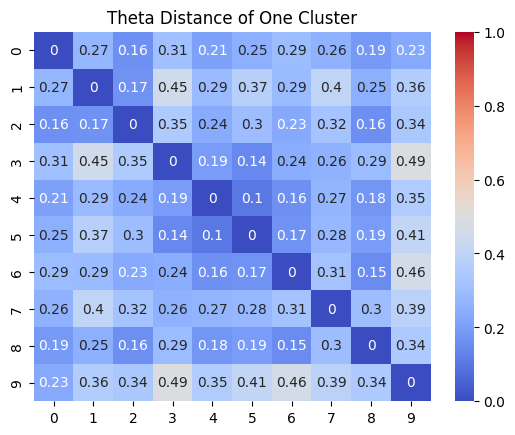

In [24]:
# One cluster

# data
data_path_1 = "./set1_one_cluster.jsonl"
gamma_list_1, theta_list_1, labels_1 = load_data_from_jsonl(data_path_1)

# represent distance
theta_array_1 = np.vstack(theta_list_1)
theta_dist_1 = pairwise_distances(theta_array_1, metric="euclidean")
sns.heatmap(theta_dist_1, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title("Theta Distance of One Cluster")
plt.show

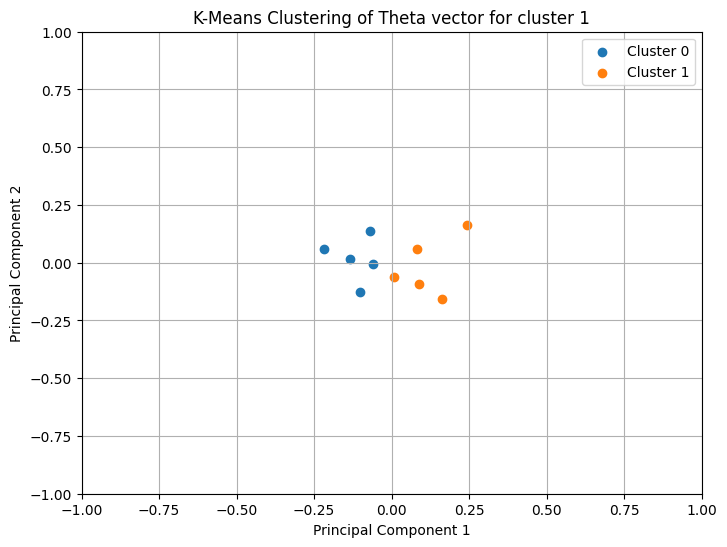

In [53]:
# using clustering and plot it

kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto')
cluster_labels = kmeans.fit_predict(theta_list_1)

# reduce 5d vectors to 2d for visualization using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(theta_list_1)

# plot the results
plt.figure(figsize=(8, 6))

# scatter plot for each cluster
for cluster_id in np.unique(cluster_labels):
    plt.scatter(
        X_pca[cluster_labels == cluster_id, 0],
        X_pca[cluster_labels == cluster_id, 1],
        label=f'Cluster {cluster_id}'
    )

plt.title('K-Means Clustering of Theta vector for cluster 1')
plt.xlabel('Principal Component 1')
plt.xlim(-1,1)
plt.ylabel('Principal Component 2')
plt.ylim(-1,1)
plt.legend()
plt.grid(True)
plt.show()


In [56]:
range(2, 11)

range(2, 11)

In [86]:
# compute the silhouette score
from sklearn.metrics import silhouette_score

# one_cluster_score = silhouette_score(theta_list_1, cluster_labels)
k_range = range(2, 10)

for i in k_range:

    kmeans_1c = KMeans(n_clusters=i, random_state=42, n_init='auto')

    # predict cluster label
    labels_1c = kmeans_1c.fit_predict(theta_list_1)
    
    one_cluster_score = silhouette_score(theta_list_1, labels_1c)
    
    print(f"Silhouette score of the one cluster dataset at K = {i}:", one_cluster_score)

Silhouette score of the one cluster dataset at K = 2: 0.24649310301997346
Silhouette score of the one cluster dataset at K = 3: 0.16383938424906916
Silhouette score of the one cluster dataset at K = 4: 0.20721269042296325
Silhouette score of the one cluster dataset at K = 5: 0.09753361936921263
Silhouette score of the one cluster dataset at K = 6: 0.09050412890558364
Silhouette score of the one cluster dataset at K = 7: 0.06064317260595912
Silhouette score of the one cluster dataset at K = 8: 0.08417644728790331
Silhouette score of the one cluster dataset at K = 9: 0.06575702875826717


<function matplotlib.pyplot.show(close=None, block=None)>

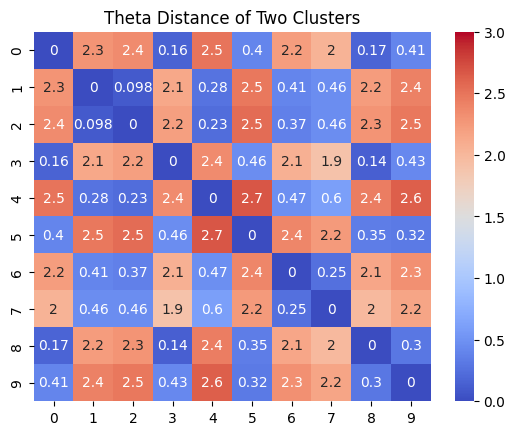

In [28]:
# Two cluster
# data
data_path_2 = "./set1_two_cluster.jsonl"
gamma_list_2, theta_list_2, labels_2 = load_data_from_jsonl(data_path_2)

# represent distance
theta_array_2 = np.vstack(theta_list_2)
theta_dist_2 = pairwise_distances(theta_array_2, metric="euclidean")
sns.heatmap(theta_dist_2, annot=True, cmap='coolwarm', vmin=0, vmax=3)
plt.title("Theta Distance of Two Clusters")
plt.show

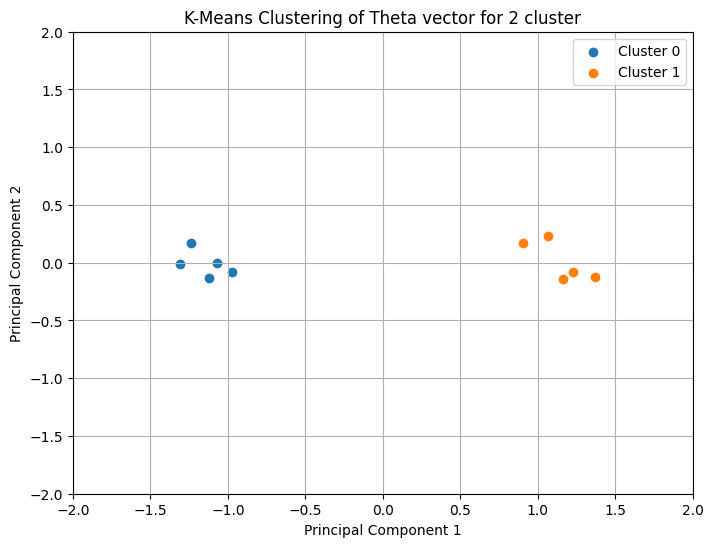

In [63]:
# using clustering and plot it

kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init='auto')
cluster_labels_2 = kmeans.fit_predict(theta_list_2)

# reduce 5d vectors to 2d for visualization using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(theta_list_2)

# plot the results
plt.figure(figsize=(8, 6))

# scatter plot for each cluster
for cluster_id in np.unique(cluster_labels_2):
    plt.scatter(
        X_pca[cluster_labels_2 == cluster_id, 0],
        X_pca[cluster_labels_2 == cluster_id, 1],
        label=f'Cluster {cluster_id}'
    )

plt.title('K-Means Clustering of Theta vector for 2 cluster')
plt.xlabel('Principal Component 1')
plt.xlim(-2,2)
plt.ylabel('Principal Component 2')
plt.ylim(-2,2)
plt.legend()
plt.grid(True)
plt.show()


In [64]:
# compare the label
print("The label of 2 lcusters Kmeans:", cluster_labels_2)

The label of 2 lcusters Kmeans: [0 1 1 0 1 0 1 1 0 0]


In [66]:
print("Label as generated 2 clusters data:", labels_2)

Label as generated 2 clusters data: [list([0, 1, 1, 0, 1, 0, 1, 1, 0, 0])]


In [81]:
inertias = []
sil_scores = []
k_range = range(2, 10)

for k in k_range:
    kmeans_2 = KMeans(n_clusters=k, random_state=42).fit(theta_list_2)
    inertias.append(kmeans_2.inertia_)
    sil_scores.append(silhouette_score(theta_list_2, kmeans_2.labels_))

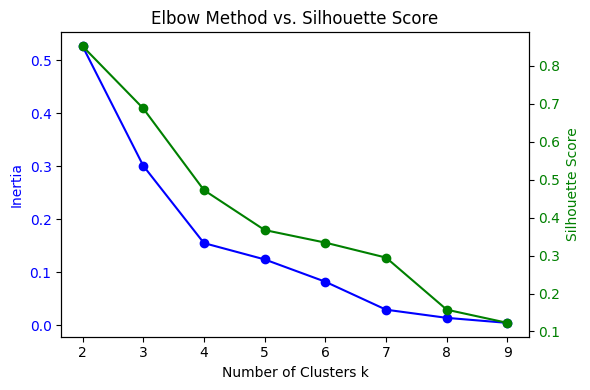

In [82]:
fig, ax1 = plt.subplots(figsize=(6, 4))

ax1.plot(k_range, inertias, 'bo-', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters k')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(k_range, sil_scores, 'go-', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='g')
ax2.tick_params(axis='y', labelcolor='g')

plt.title('Elbow Method vs. Silhouette Score')
fig.tight_layout()
plt.show()

## 3 cluster

<function matplotlib.pyplot.show(close=None, block=None)>

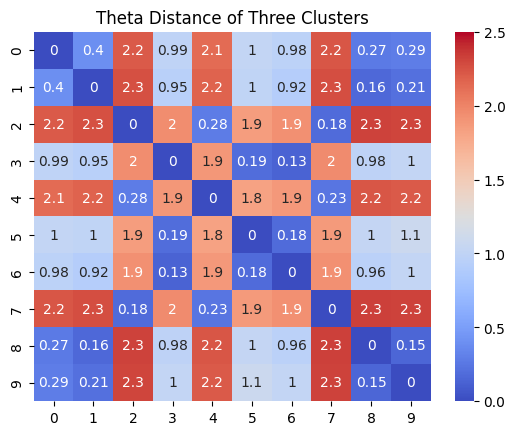

In [70]:
# 3 cluster
# data
data_path_3 = "./set1_three_cluster.jsonl"
gamma_list_3, theta_list_3, labels_3 = load_data_from_jsonl(data_path_3)

# represent distance
theta_array_3 = np.vstack(theta_list_3)
theta_dist_3 = pairwise_distances(theta_array_3, metric="euclidean")
sns.heatmap(theta_dist_3, annot=True, cmap='coolwarm', vmin=0, vmax=2.5)
plt.title("Theta Distance of Three Clusters")
plt.show

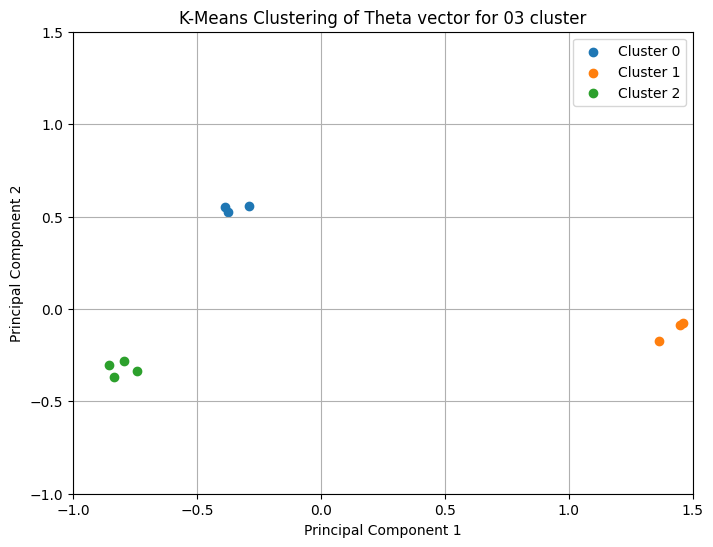

In [72]:
# using clustering and plot it

kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init='auto')
cluster_labels_3 = kmeans.fit_predict(theta_list_3)

# reduce 5d vectors to 2d for visualization using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(theta_list_3)

# plot the results
plt.figure(figsize=(8, 6))

# scatter plot for each cluster
for cluster_id in np.unique(cluster_labels_3):
    plt.scatter(
        X_pca[cluster_labels_3 == cluster_id, 0],
        X_pca[cluster_labels_3 == cluster_id, 1],
        label=f'Cluster {cluster_id}'
    )

plt.title('K-Means Clustering of Theta vector for 03 cluster')
plt.xlabel('Principal Component 1')
plt.xlim(-1,1.5)
plt.ylabel('Principal Component 2')
plt.ylim(-1,1.5)
plt.legend()
plt.grid(True)
plt.show()


In [73]:
# compare the label
print("The label of 2 lcusters Kmeans:", cluster_labels_3)
print("Label as generated 2 clusters data:", labels_3)

The label of 2 lcusters Kmeans: [2 2 1 0 1 0 0 1 2 2]
Label as generated 2 clusters data: [list([0, 0, 1, 2, 1, 2, 2, 1, 0, 0])]


In [89]:
inertias = []
sil_scores = []
k_range = range(2, 10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42).fit(theta_list_3)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(theta_list_3, kmeans.labels_))

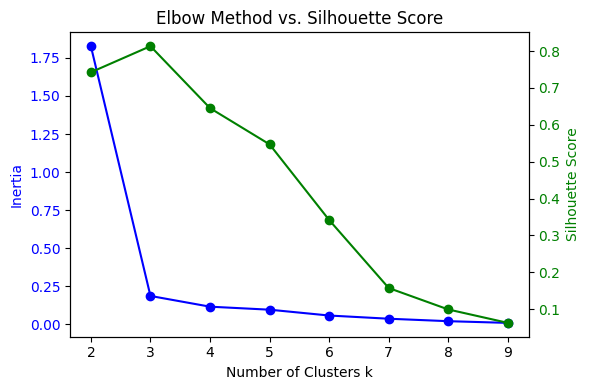

In [90]:
fig, ax1 = plt.subplots(figsize=(6, 4))

# elbow
ax1.plot(k_range, inertias, 'bo-', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters k')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# silhouette Score
ax2 = ax1.twinx()
ax2.plot(k_range, sil_scores, 'go-', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='g')
ax2.tick_params(axis='y', labelcolor='g')


plt.title('Elbow Method vs. Silhouette Score')
fig.tight_layout()
plt.show()